# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import time
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [35]:
# Path ke file dataset hasil clustering
file_path = "Dataset_inisiasi.csv"

# Periksa apakah file ada sebelum memuat dataset
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File '{file_path}' tidak ditemukan!")

# Memuat dataset ke dalam DataFrame
df = pd.read_csv(file_path)

# Pastikan dataset tidak kosong
if df.empty:
    raise ValueError("Dataset kosong! Periksa kembali file CSV.")

# Verifikasi kolom 'cluster' ada (kriteria 5)
if 'cluster' not in df.columns:
    raise ValueError("Kolom 'cluster' tidak ditemukan. Pastikan dataset sudah melalui proses clustering!")

# Verifikasi kolom PCA (opsional, untuk memastikan kriteria 6)
pca_columns = ['pca_1', 'pca_2']
if any(col in df.columns for col in pca_columns):
    print("Peringatan: Kolom PCA ada dalam dataset. Pastikan tidak digunakan sebagai fitur nanti.")

# Menampilkan 5 baris pertama untuk verifikasi
print("Dataset berhasil dimuat. Berikut 5 baris pertama:")
print(df.head())

Peringatan: Kolom PCA ada dalam dataset. Pastikan tidak digunakan sebagai fitur nanti.
Dataset berhasil dimuat. Berikut 5 baris pertama:
    tahun      peng peng_binned  provinsi_BALI  provinsi_BANTEN  \
0  2007.0  195176.0      rendah          False            False   
1  2008.0  218781.0      rendah          False            False   
2  2009.0  247427.0      rendah          False            False   
3  2010.0  275749.0      rendah          False            False   
4  2011.0  308000.0      rendah          False            False   

   provinsi_BENGKULU  provinsi_DI YOGYAKARTA  provinsi_DKI JAKARTA  \
0              False                   False                 False   
1              False                   False                 False   
2              False                   False                 False   
3              False                   False                 False   
4              False                   False                 False   

   provinsi_GORONTALO  provinsi_INDONES

# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [36]:
# Pastikan dataset tidak kosong sebelum splitting
if df.empty:
    raise ValueError("Dataset kosong! Periksa kembali dataset sebelum membagi data.")

# Pastikan kolom yang diperlukan ada dalam dataset
required_columns = ["cluster"]  # Hanya perlu memastikan 'cluster' ada
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise KeyError(f"Kolom {missing_columns} tidak ditemukan dalam dataset! Pastikan dataset benar.")

# Memilih fitur (X) dan target (y)
# Menghapus kolom yang tidak diperlukan: peng_binned, pca_1, pca_2
X = df.drop(columns=["peng_binned", "cluster", "pca_1", "pca_2"])
y = df["cluster"]  # Target klasifikasi adalah hasil clustering (kriteria 5)

# Pastikan tidak ada missing values dalam fitur atau target sebelum split
if X.isna().sum().sum() > 0 or y.isna().sum() > 0:
    raise ValueError("Dataset memiliki nilai NaN! Pastikan semua nilai telah diproses sebelum splitting.")

# Membagi dataset menjadi 80% training dan 20% testing, menjaga keseimbangan kelas
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Konfirmasi ukuran dataset setelah pembagian
print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 3696
Jumlah data uji: 924


# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [37]:
# Inisialisasi kedua model
dt_model = DecisionTreeClassifier(random_state=42, max_depth=10, min_samples_split=5)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)

# Pastikan data latih tidak kosong dan target adalah 'cluster'
if X_train.empty or y_train.empty or 'cluster' not in df.columns:
    raise ValueError("Data latih kosong atau kolom 'cluster' tidak ditemukan! Pastikan Data Splitting sudah benar.")

# Melatih model Decision Tree
print("\nMelatih model Decision Tree untuk memprediksi cluster...")
start_time = time.time()
dt_model.fit(X_train, y_train)  # y_train sekarang adalah kolom 'cluster'
end_time = time.time()
print(f"Decision Tree berhasil dilatih dalam {end_time - start_time:.2f} detik.")

# Melatih model Random Forest
print("\nMelatih model Random Forest untuk memprediksi cluster...")
start_time = time.time()
rf_model.fit(X_train, y_train)  # y_train sekarang adalah kolom 'cluster'
end_time = time.time()
print(f"Random Forest berhasil dilatih dalam {end_time - start_time:.2f} detik.")


Melatih model Decision Tree untuk memprediksi cluster...
Decision Tree berhasil dilatih dalam 0.01 detik.

Melatih model Random Forest untuk memprediksi cluster...
Random Forest berhasil dilatih dalam 0.42 detik.


Tulis narasi atau penjelasan algoritma yang Anda gunakan.

Penjelasan Algoritma Klasifikasi

Dalam proyek ini, saya menggunakan Decision Tree dan Random Forest sebagai algoritma klasifikasi.

🔹 Decision Tree (Pohon Keputusan)

  - Memecah data berdasarkan fitur yang paling informatif hingga mencapai keputusan akhir.

  - Kelebihan: Cepat, mudah dipahami.

  - Kekurangan: Rentan terhadap overfitting.

🔹 Random Forest

  - Menggabungkan banyak Decision Tree untuk meningkatkan akurasi dan stabilitas.

  - Kelebihan: Lebih akurat, mengurangi overfitting.

  - Kekurangan: Waktu pelatihan lebih lama.

## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.


Decision Tree - Evaluasi (Target: Cluster):
Accuracy  : 0.9935
Precision : 0.9935
Recall    : 0.9935
F1-Score  : 0.9935

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       362
           1       0.99      1.00      0.99       396
           2       1.00      1.00      1.00       166

    accuracy                           0.99       924
   macro avg       0.99      0.99      0.99       924
weighted avg       0.99      0.99      0.99       924



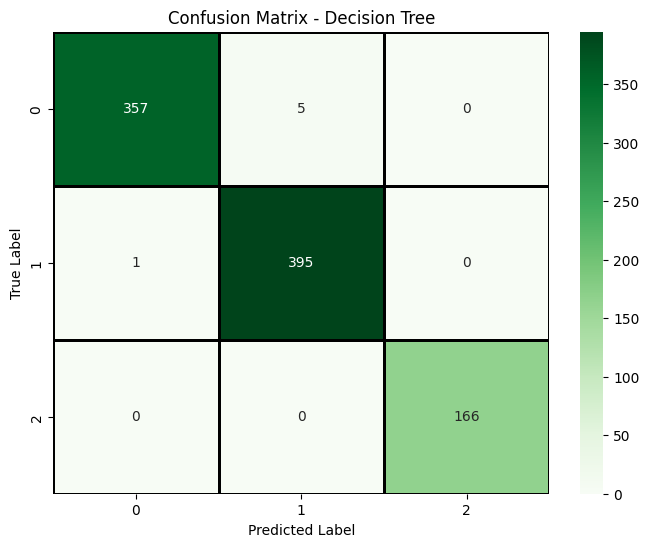


Random Forest - Evaluasi (Target: Cluster):
Accuracy  : 0.9859
Precision : 0.9862
Recall    : 0.9859
F1-Score  : 0.9859

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       362
           1       0.97      1.00      0.99       396
           2       1.00      0.99      0.99       166

    accuracy                           0.99       924
   macro avg       0.99      0.99      0.99       924
weighted avg       0.99      0.99      0.99       924



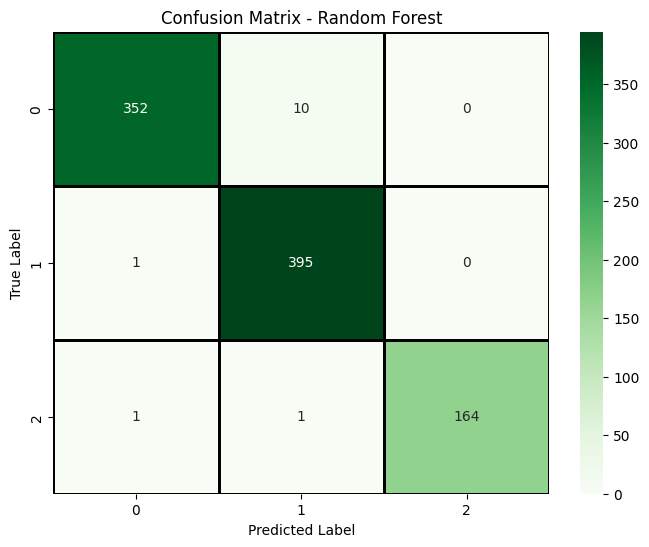

In [38]:
# Dictionary untuk menyimpan hasil evaluasi
eval_results = {}

# Fungsi evaluasi model
def evaluate_model(model, model_name):
    # Melakukan prediksi pada data uji
    y_pred = model.predict(X_test)

    # Menghitung metrik evaluasi (target: cluster)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted")
    f1 = f1_score(y_test, y_pred, average="weighted")
    conf_matrix = confusion_matrix(y_test, y_pred)

    # Simpan hasil evaluasi
    eval_results[model_name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

    # Menampilkan hasil evaluasi
    print(f"\n{model_name} - Evaluasi (Target: Cluster):")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    # Tampilkan classification report detail
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt='d',
        cmap='Greens',
        linewidths=1,
        linecolor='black'
    )
    # Use model_name instead of title for the plot title
    plt.title(f"Confusion Matrix - {model_name}", fontsize=12)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

# Evaluasi Decision Tree
evaluate_model(dt_model, "Decision Tree")

# Evaluasi Random Forest
evaluate_model(rf_model, "Random Forest")

Tulis hasil evaluasi algoritma yang digunakan, jika Anda menggunakan 2 algoritma, maka bandingkan hasilnya.

Decision Tree :

- Accuracy	: 99.35%
- Precision	: 99.35%
- Recall	  : 99.35%
- F1-Score  : 99.35%

Random Forest :
- Accuracy	: 98.59%
- Precision	: 98.59%
- Recall	  : 98.59%
- F1-Score  : 98.59%

Analisis Perbandingan:

- Decision Tree unggul secara konsisten pada seluruh metrik evaluasi dalam konteks ini. Dengan akurasi hampir sempurna dan performa yang stabil di semua cluster, Decision Tree menjadi pilihan terbaik untuk mengklasifikasikan data berdasarkan hasil clustering yang telah dilakukan.

- Decision Tree lebih optimal: akurat, cepat, dan stabil untuk data ini

- Random Forest kurang efektif: kompleksitasnya tidak meningkatkan performa


## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik


Best Parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}

Decision Tree (Tuned) - Evaluasi Model:
Accuracy  : 0.9935
Precision : 0.9935
Recall    : 0.9935
F1-Score  : 0.9935

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       362
           1       0.99      1.00      0.99       396
           2       1.00      1.00      1.00       166

    accuracy                           0.99       924
   macro avg       0.99      0.99      0.99       924
weighted avg       0.99      0.99      0.99       924



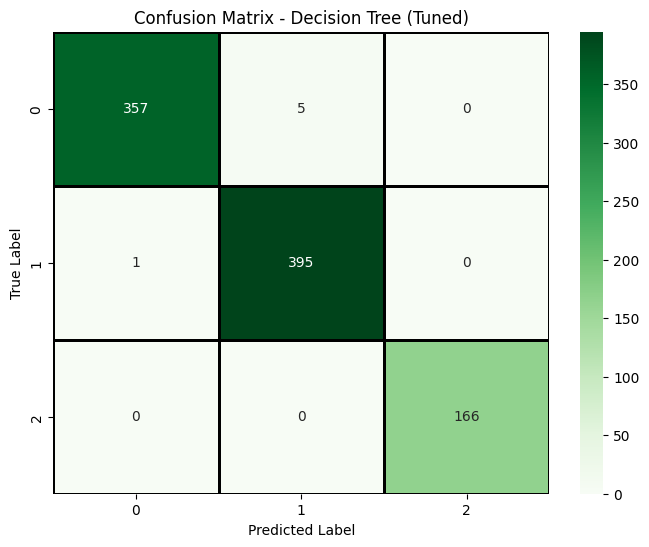

In [39]:
# Fungsi untuk evaluasi model
def evaluate_model(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=1)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"\n{title} - Evaluasi Model:")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    # Tampilkan classification report detail
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

   # Visualisasi Confusion Matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt='d',
        cmap='Greens',
        linewidths=1,
        linecolor='black'
    )
    plt.title(f"Confusion Matrix - {title}", fontsize=12)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

# Data Splitting dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Hyperparameter tuning dengan GridSearchCV
param_grid = {
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 5, 10, 15],
    'criterion': ['gini', 'entropy']
}

dt = DecisionTreeClassifier(random_state=42)

# Cari parameter terbaik dengan GridSearchCV
grid_search = GridSearchCV(
    dt, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1
)
grid_search.fit(X_train, y_train)
best_dt = grid_search.best_estimator_

print(f"\nBest Parameters: {grid_search.best_params_}")

# Evaluasi Model Setelah Hyperparameter Tuning
evaluate_model(best_dt, X_test, y_test, "Decision Tree (Tuned)")

## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.


 Evaluasi Model: Decision Tree (Setelah Tuning)
 Accuracy  : 0.9935
 Precision : 0.9935
 Recall    : 0.9935
 F1 Score  : 0.9935

 Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       362
           1       0.99      1.00      0.99       396
           2       1.00      1.00      1.00       166

    accuracy                           0.99       924
   macro avg       0.99      0.99      0.99       924
weighted avg       0.99      0.99      0.99       924



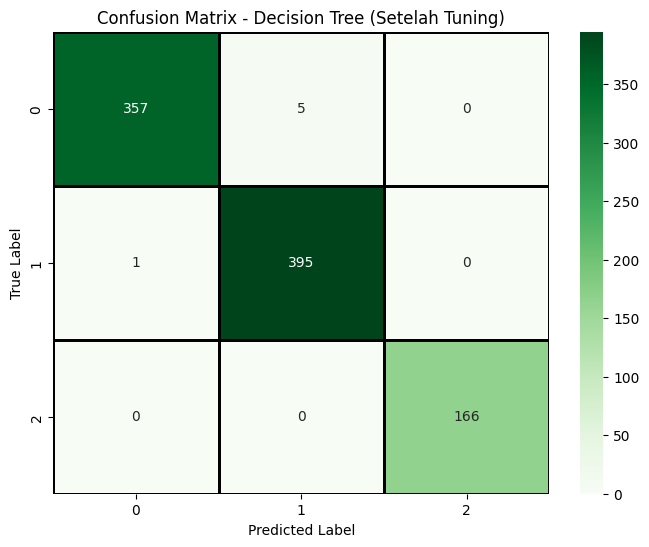

In [40]:
# Pastikan model hasil tuning dan pruning sudah didefinisikan sebelumnya
if 'best_dt' not in globals():
    raise ValueError("Error: Model best_dt belum didefinisikan! Pastikan GridSearchCV telah selesai.")

# Fungsi Evaluasi Model
def evaluate_and_visualize(model, X_test, y_test, title):
    y_pred = model.predict(X_test)

    # Menghitung metrik evaluasi
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=1)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Menampilkan hasil evaluasi
    print(f"\n Evaluasi Model: {title}")
    print(f" Accuracy  : {accuracy:.4f}")
    print(f" Precision : {precision:.4f}")
    print(f" Recall    : {recall:.4f}")
    print(f" F1 Score  : {f1:.4f}")

    # Menampilkan Classification Report lengkap
    print("\n Classification Report:\n", classification_report(y_test, y_pred, zero_division=1))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt='d',
        cmap='Greens',
        linewidths=1,
        linecolor='black'
    )
    plt.title(f"Confusion Matrix - {title}", fontsize=12)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

# Evaluasi Model Setelah Tuning
evaluate_and_visualize(best_dt, X_test, y_test, "Decision Tree (Setelah Tuning)")


## **e. Analisis Hasil Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Bandingkan hasil evaluasi sebelum dan setelah tuning (jika dilakukan).

  Decision Tree (Sebelum Tuning) :
  - Accuracy  : 0.9935
  - Precision :	0.9935
  - Recall    : 0.9935
  - F1-Score  : 0.9935
  
  Decision Tree (Stelah Tuning) :
  - Accuracy	: 0.9935
  - Precision	: 0.9935
  - Recall		: 0.9935
  - F1-Score	: 0.9935

  Tidak terjadi peningkatan performa, karena model sudah sangat optimal sejak awal. Tuning hanya membantu memastikan bahwa parameter yang digunakan memang sudah tepat.
2. Identifikasi kelemahan model, seperti:
  - Tidak ada kelemahan signifikan yang terlihat dari hasil evaluasi. Semua kelas memiliki nilai precision, recall, dan f1-score mendekati 1.00.
  - Apakah model mengalami overfitting atau underfitting?
    - Berdasarkan hasil evaluasi pada data uji, tidak terindikasi overfitting maupun underfitting.
3. Berikan rekomendasi tindakan lanjutan, seperti mengumpulkan data tambahan atau mencoba algoritma lain jika hasil belum memuaskan.
    - Tetap gunakan model Decision Tree dengan parameter terbaik, karena hasilnya sangat baik.
    - Untuk validasi lebih kuat, dapat dilakukan cross-validation tambahan atau pengujian dengan dataset baru.gunakan teknik ensemble learning.
    - Jika ingin eksplorasi lebih lanjut, bisa mencoba algoritma lain seperti XGBoost atau Gradient Boosting sebagai pembanding.
   